
# Group analysis with MNE-Python


The aim of this lecture is to show you how to do group analysis
and statistics with MNE-Python.

    Authors: Marijn van Vliet, Britta Westner, Alexandre Gramfort, Denis A. Engemann, Mainak Jas, Hicham Janati

    License: BSD (3-clause)
   

In [1]:
# This makes figures appear inside the notebook instead of in a new window.
%matplotlib inline

# We set the log-level of MNE-Python to 'warning' so the output is less verbose:
import mne
mne.set_log_level('error')

# Disable all warnings so they don't end up in the HTML.
import warnings
warnings.filterwarnings("ignore")

# Specify rendering backends
mne.viz.set_browser_backend("qt")

In [29]:
# These are the Python packages we will use in this session.
import numpy as np  # for numerical computations
import matplotlib.pyplot as plt  # for making custom figures
import mne  # for MEG and EEG data analysis

# Change the following path to where you extracted mne_course_data.zip
data_path = "./data"

# This is the FreeSurfer "subjects" folder, where the program expects the MRI data to be
subjects_dir = f"{data_path}/freesurfer"

# Files for the group analysis
group_path = f"{data_path}/group_analysis"

## Sensor-level grand averages

The evoked data for all participants can be found in the `group_analysis` folder. Let's look at one of them:

In [3]:
subject = 3  # load the evokeds of subject 3
evokeds = mne.read_evokeds(f"{group_path}/sub-{subject:02d}_list-ave.fif")
evokeds

[<Evoked | 'face' (average, N=564), -0.2 – 1 s, baseline -0.2 – 0 s, 376 ch, ~8.0 MiB>,
 <Evoked | 'scrambled' (average, N=274), -0.2 – 1 s, baseline -0.2 – 0 s, 376 ch, ~8.0 MiB>,
 <Evoked | 'famous' (average, N=283), -0.2 – 1 s, baseline -0.2 – 0 s, 376 ch, ~8.0 MiB>,
 <Evoked | 'unfamiliar' (average, N=281), -0.2 – 1 s, baseline -0.2 – 0 s, 376 ch, ~8.0 MiB>]

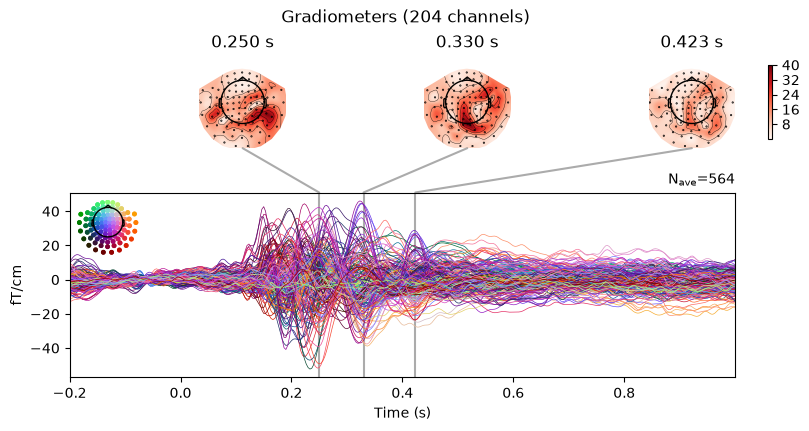

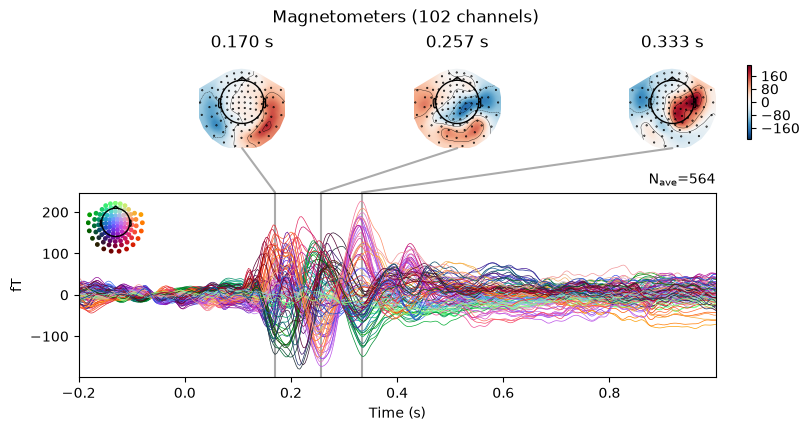

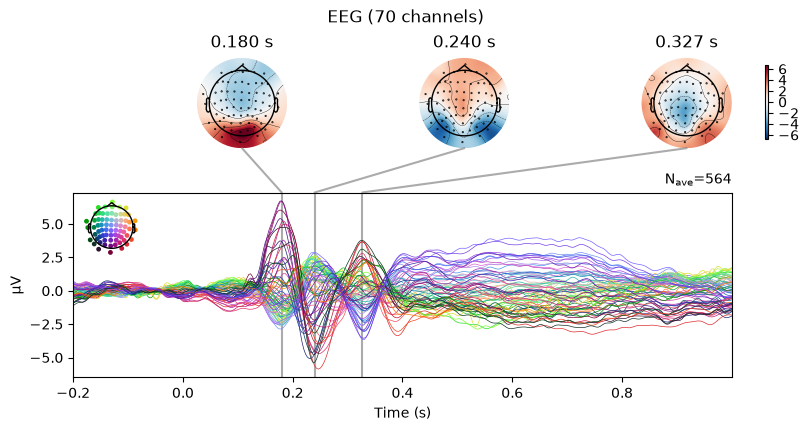

[<Figure size 800x420 with 6 Axes>,
 <Figure size 800x420 with 6 Axes>,
 <Figure size 800x420 with 6 Axes>]

In [4]:
evokeds[0].plot_joint()

Before we start averaging across subjects, let's get an overview to see if there are any datasets that look problematic.

In [5]:
# Make a list of all the subjects we have data for.
subjects = [f"sub-{subject:02d}" for subject in range(1, 17)]
print(subjects)

['sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05', 'sub-06', 'sub-07', 'sub-08', 'sub-09', 'sub-10', 'sub-11', 'sub-12', 'sub-13', 'sub-14', 'sub-15', 'sub-16']


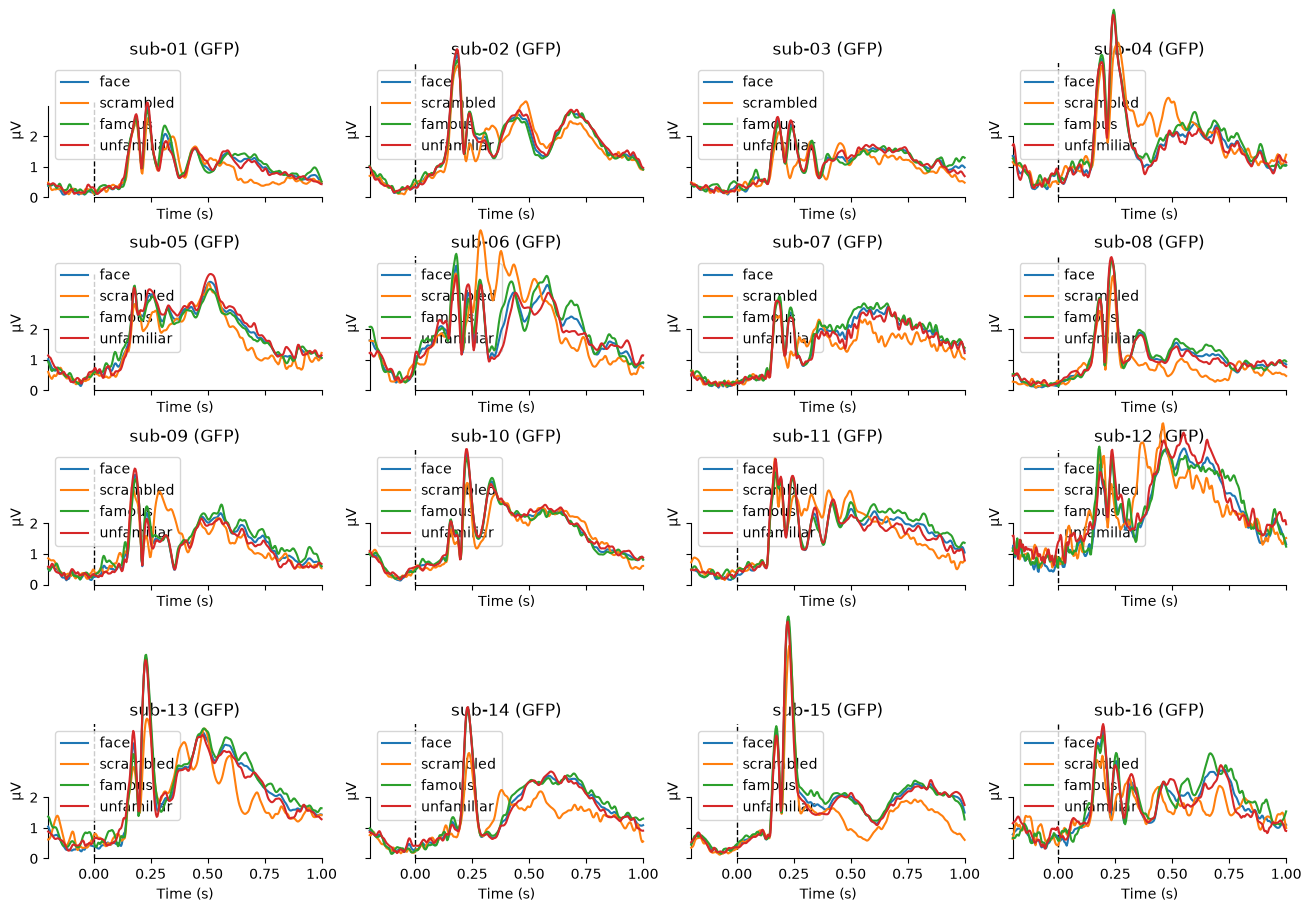

In [6]:
ch_type = "eeg"  # we pick the EEG channels here
fig, axes = plt.subplots(4, 4, figsize=(13, 9), sharex=True, sharey=True, layout="constrained")
for ax, sub in zip(axes.ravel(), subjects):
    evokeds = mne.read_evokeds(f"{group_path}/{sub}_list-ave.fif")
    mne.viz.plot_compare_evokeds(evokeds, picks=ch_type, show=False, axes=ax, title=sub)

<div class='alert alert-success'>
    <b>EXERCISE</b>:
     <ul>
      <li>Compute the same type of GFP plots for MEG Magnetometers</li>
      <li>Do you see any problematic datasets?</li>
    </ul>
</div>

### Look at grand averages

Grand averages are obtained by averaging across subjects. There is a dedicated MNE-Python function for it that verifies that all [`mne.Evoked`](https://mne.tools/stable/generated/mne.Evoked.html) objects have the same channels and times defined.

In [7]:
mne.grand_average?

Signature: mne.grand_average(all_inst, interpolate_bads=True, drop_bads=True)
Docstring:
Make grand average of a list of Evoked, AverageTFR, or Spectrum data.

For :class:`mne.Evoked` data, the function interpolates bad channels based on the
``interpolate_bads`` parameter. If ``interpolate_bads`` is True, the grand average
file will contain good channels and the bad channels interpolated from the good
MEG/EEG channels.
For :class:`mne.time_frequency.AverageTFR` and :class:`mne.time_frequency.Spectrum`
data, the function takes the subset of channels not marked as bad in any of the
instances.

The ``grand_average.nave`` attribute will be equal to the number of datasets used to
calculate the grand average.

.. note:: A grand average evoked should not be used for source localization.

Parameters
----------
all_inst : list of Evoked, AverageTFR or Spectrum
    The datasets.

    .. versionchanged:: 1.10.0
        Added support for :class:`~mne.time_frequency.Spectrum` objects.

interpolate_

In [8]:
all_evokeds = dict()
ga_evokeds = dict()
for condition in ["face", "scrambled", "famous", "unfamiliar"]:
    evokeds = list()
    for sub in subjects:
        evokeds.append(
            mne.read_evokeds(f"{group_path}/{sub}_list-ave.fif", condition=condition)
        )
    assert len(evokeds) == len(subjects)  # do we have the evokeds for everyone?
    all_evokeds[condition] = evokeds
    ga_evokeds[condition] = mne.grand_average(evokeds)

ga_evokeds

{'face': <Evoked | 'Grand average (n = 16)' (average, N=16), -0.2 – 1 s, baseline -0.2 – 0 s, 376 ch, ~8.0 MiB>,
 'scrambled': <Evoked | 'Grand average (n = 16)' (average, N=16), -0.2 – 1 s, baseline -0.2 – 0 s, 376 ch, ~8.0 MiB>,
 'famous': <Evoked | 'Grand average (n = 16)' (average, N=16), -0.2 – 1 s, baseline -0.2 – 0 s, 376 ch, ~8.0 MiB>,
 'unfamiliar': <Evoked | 'Grand average (n = 16)' (average, N=16), -0.2 – 1 s, baseline -0.2 – 0 s, 376 ch, ~8.0 MiB>}

Show the grand average evoked response for each condition:

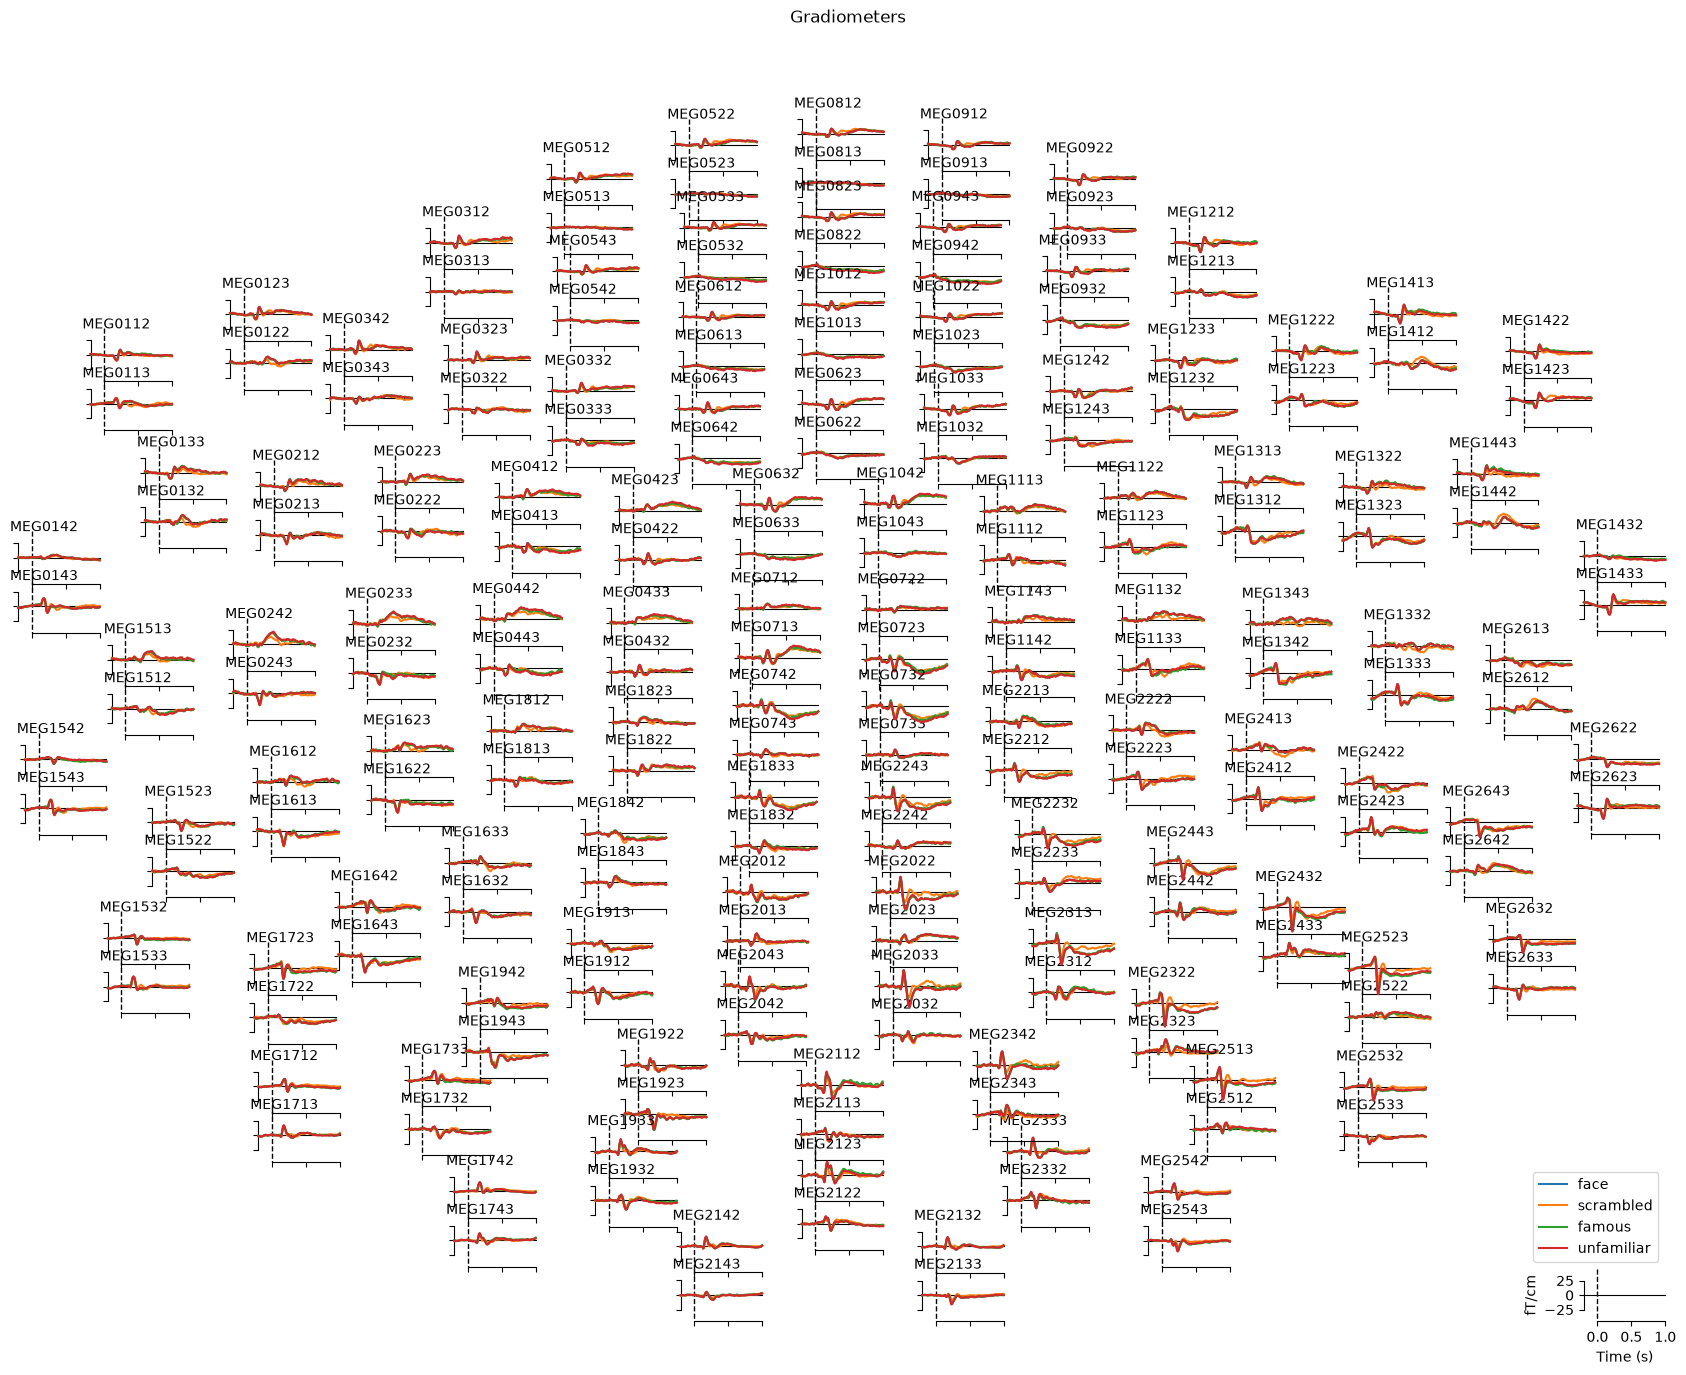

[<Figure size 1800x1400 with 205 Axes>]

In [9]:
mne.viz.plot_compare_evokeds(ga_evokeds, picks="grad", axes="topo")

<div class='alert alert-success'>
    <b>EXERCISE</b>:
     <ul>
      <li>Compute the grand-average contrast between the "scrambled" versus "face" conditions. Remember the <code>mne.combine_evoked</code> function.</li>
     </ul>
</div>

## Sensor-level statistics

MNE-Python's statistics API is currently quite low level, operating on numpy arrays. To do statistics, we will be getting the data from an MNE-Python object to a numpy array, and putting a numpy array in an MNE-Python object.

### Sensor level $t$-map

Before moving on to something more complicated, a good first step is to create a [$t$-map](https://en.wikipedia.org/wiki/T-statistic) to see where and when statistically significant differences between conditions may happen. You can then see if significant differences line up with peaks in the evoked response as expected. We will do paired t-tests between the responses to **scrambled stimuli vs face stimuli**.

We start by getting the data from the `Evoked` objects for both conditions:

In [10]:
import numpy as np  # using "raw" numpy now

scrambled = np.array([evoked.data for evoked in all_evokeds["scrambled"]])
face = np.array([evoked.data for evoked in all_evokeds["face"]])
contrast = scrambled - face

print(contrast.shape)

(16, 376, 361)


To do a paired t-test, we take compare the contrast against 0:

In [11]:
tvalues = mne.stats.ttest_1samp_no_p(contrast)
print(tvalues.shape)

(376, 361)


To visualize the t-values, we need to pack them into an MNE-Python `Evoked` object:

In [12]:
mne.EvokedArray?

Init signature:
mne.EvokedArray(
    data: numpy.ndarray,
    info: mne._fiff.meas_info.Info,
    tmin: float = 0.0,
    comment: str | None = '',
    nave: int = 1,
    kind: str = 'average',
    baseline: tuple[float | None, float | None] | None = None,
    *,
    verbose: bool | str | int | None = None,
)
Docstring:     
Evoked object from numpy array.

Parameters
----------
data : array of shape (n_channels, n_times)
    The channels' evoked response. See notes for proper units of measure.

info : mne.Info
    The :class:`mne.Info` object with information about the sensors and methods of measurement. Consider using :func:`mne.create_info` to populate this
    structure.
tmin : float
    Start time before event. Defaults to 0.
comment : str
    Comment on dataset. Can be the condition. Defaults to ''.
nave : int
    Number of averaged epochs. Defaults to 1.
kind : str
    Type of data, either average or standard_error. Defaults to 'average'.

baseline : None | tuple of length 2
    

We need an `info` object to attach to the `Evoked` object. A good choice here is to take one from the grand average evokeds:

In [13]:
info = ga_evokeds["face"].info
tmin = ga_evokeds["face"].tmin
times = ga_evokeds["face"].times

Now we can store the `tmap` inside an `Evoked` object:

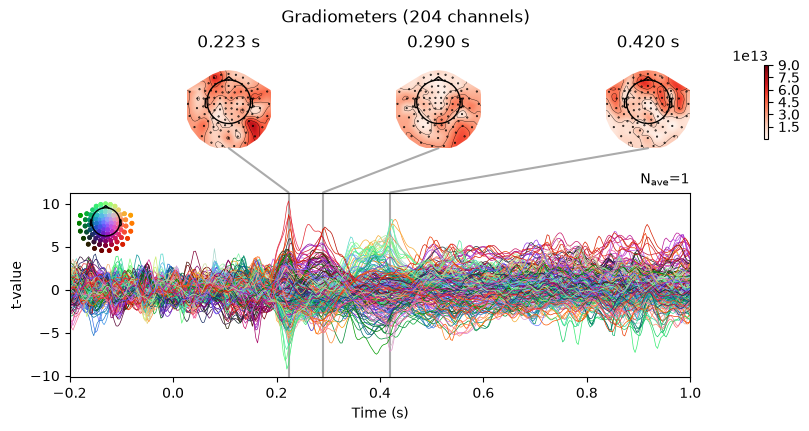

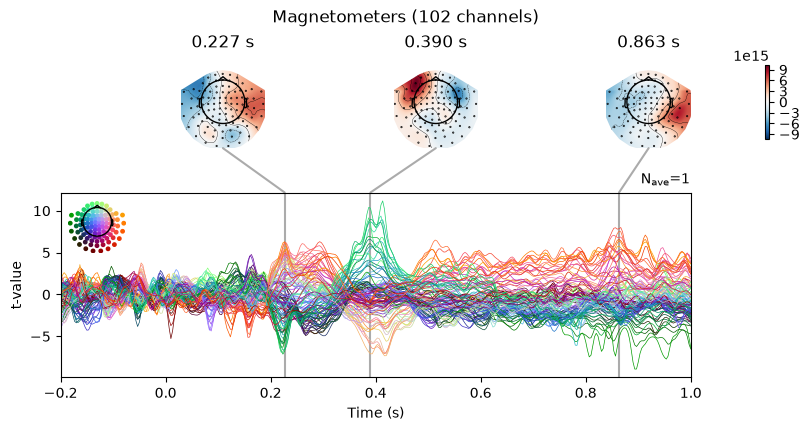

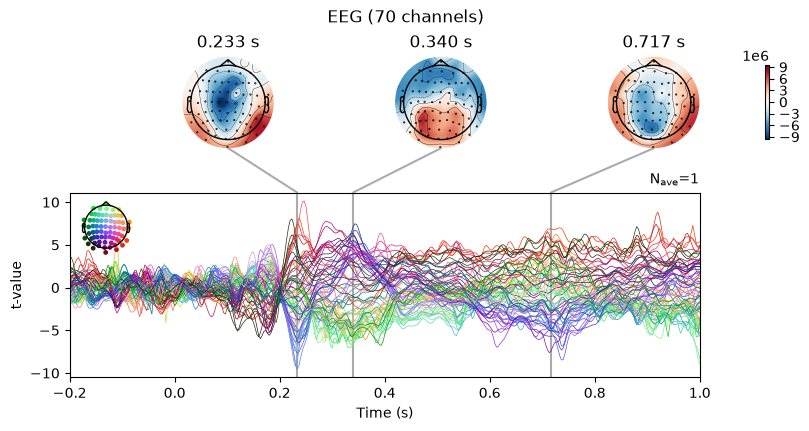

[<Figure size 800x420 with 6 Axes>,
 <Figure size 800x420 with 6 Axes>,
 <Figure size 800x420 with 6 Axes>]

In [14]:
tmap = mne.EvokedArray(tvalues, info=info, tmin=tmin, comment="tmap")

# Plot the t-map. Set the scalings and units to the appropriate values.
tmap.plot_joint(ts_args=dict(scalings=1, units="t-value"))

There are some decently high t-values in our map (>3) for which we can be quite certain the effects are statistically significant. Of course, we computed thousands of t-values and so even by chance there should be some high ones. Note however that we are not interpreting individual t-values in this map, but rather trends of peaks of t-values rising and falling and groups of sensors with high t-values. If we found an isolated high t-value at a single time point on one single channel, we would not trust it. This is the reasonsing behind cluster-based testing.

### Cluster-based permutation test on one channel

We'll start with a single channel, MEG2523. We will run a cluster-permutation test of our (`scrambled - face`) contrast against 0, which means we are doing a paired test.

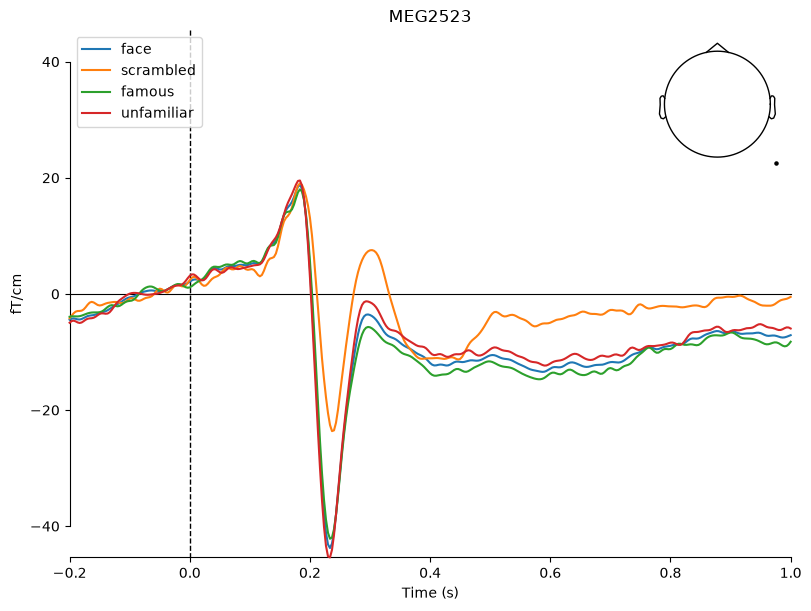

In [24]:
channel = "MEG2523"
mne.viz.plot_compare_evokeds(ga_evokeds, picks=channel);

The most important parameter for our test is the cluster `threshold` value. This will determine which timepoints belong to the same cluster. This value we set ourselves as analysts and incorporates our intuition about which t-values are part of the same "peak" or other feature that is somehow meaningful to us. In this case, the peak around 0.2-0.3 ms looks meaningful, so let's set the threshold such that this peak will be captured in a single cluster. Since the threshold is based on the $t$-map, let's look at it for our chosen channel:

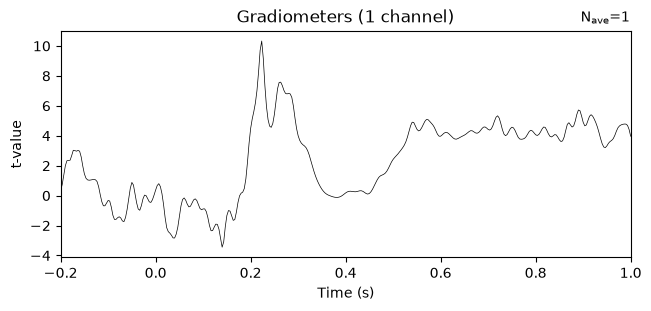

In [23]:
tmap.plot(picks=channel, scalings=1, units="t-value");

If we want to capture the peak around 0.2-0.3 ms, a threshold of 4 seems appropriate. Any higher and we would split the peak into two clusters.

In [17]:
threshold = 4

To run the test, we isolate the data for our chosen channel into a NumPy array:

In [33]:
channel_index = info.ch_names.index(channel)
scrambled_single_chan = scrambled[:, channel_index, :]
face_single_chan = face[:, channel_index, :]
contrast_single_chan = scrambled_single_chan - face_single_chan

Now we have everything to run our statistics!

In [19]:
cluster_stats = mne.stats.permutation_cluster_1samp_test(
    contrast_single_chan, 
    threshold=threshold, #
    n_jobs=-1, # use all CPU cores available
    verbose=False, 
    n_permutations=5000, # number of permutations to run 
    seed=34892,  # pick a different seed for your own projects
)

T_obs, clusters, cluster_p_values, _ = cluster_stats

To visualize results from out one-channel test, we give you this piece of matplotlib code. MNE-Python is currently lacking a good API for this and we are hard at work to fix that.

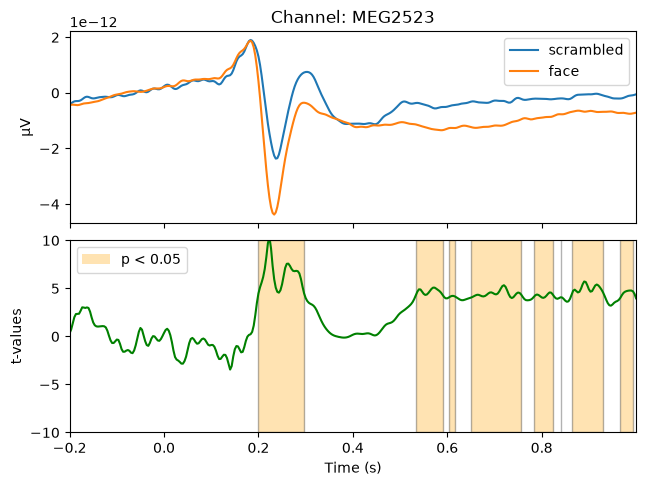

In [20]:
import matplotlib
# set up the figure
fig, axes = plt.subplots(2, sharex=True)

# on first axis: plot the data (contrast averaged across datasets)
ax = axes[0]
ax.plot(times, scrambled_single_chan.mean(axis=0), label="scrambled")
ax.plot(times, face_single_chan.mean(axis=0), label="face")
ax.set(title=f"Channel: {channel}", ylabel="μV")
ax.legend()

# on second axis: plot the clusters.

ax = axes[1]
# enumerate across the clusters
for ii, cluster_ii in enumerate(clusters):
    c = cluster_ii[0]

    # check if the matching p-value is smaller than some critical value:
    # if so, color the stretch of time red.
    critical_value = 0.05
    if cluster_p_values[ii] < critical_value:
        fill_color = "orange"
    else:
        fill_color = "white"
        
    ax.axvspan(times[c[0]], times[c[-1] - 1], fc=fill_color, ec="black", alpha=0.3)

# plot the t-values 
hf = ax.plot(times, T_obs, color="green")

# set legend, axes, and show
legend_patch = matplotlib.patches.Patch(facecolor='orange', alpha=0.3)
ax.legend([legend_patch], [f"p < {critical_value}"], loc="upper left", ncol=1)
ax.set(xlabel="Time (s)", ylabel="t-values", ylim=[-10., 10.], xlim=times[[0, -1]])
fig.tight_layout(pad=0.5)
plt.show()

### Interpreting the outcome of a cluster-based permutation test

We have clusters with an associated $p$-value < 0.05. This means the outcome of our test is that there is a statistically significant difference between the scrambled and face conditions. While we can visualize the clusters for additional context to this result, remember that we defined the span of these clusters ourselves when we picked the `threshold` value. They are not an "outcome" of this test. To clear up a common misconception: the outcome of the test applies to **all the data we fed into the test**, which in this case mean all the timepoints at our chosen channel. If we want a more specific result, e.g. "is the difference in the peak at 0.2-0.3 ms significant?", then we must re-run the test and only feed in the data from that time-span.

<div class='alert alert-success'>
    <b>EXERCISE</b>:
     <ul>
      <li>Perform the cluster-based permutation test between the "famous" versus "unfamiliar" conditions. For this you need to start with making the t-map and set an appropriate threshold.</li>
    </ul>
</div>

## Source level grand averages

Computing the grand-average source estimates is very similar as we did with the sensor-level evokeds. However, this time we can not use the `mne.grand_average()` function, but rather use `np.mean()`. Also, we must make sure to only average source estimates that have been morphed to the same template brain (`fsaverage` in our case).

In [27]:
all_stcs = dict()
ga_stcs = dict()
for condition in ["face", "scrambled"]:
    stcs = list()
    for sub in subjects:
        stcs.append(
            mne.read_source_estimate(f"{group_path}/{sub}_cond-{condition}_morphed")
        )
    assert len(stcs) == len(subjects)  # do we have the evokeds for everyone?
    all_stcs[condition] = stcs
    ga_stcs[condition] = np.mean(stcs)

ga_stcs

{'face': <SourceEstimate | 20484 vertices, tmin : -200.0 (ms), tmax : 999.9999713897707 (ms), tstep : 3.3333332538604736 (ms), data shape : (20484, 361), ~28.4 MiB>,
 'scrambled': <SourceEstimate | 20484 vertices, tmin : -200.0 (ms), tmax : 999.9999713897707 (ms), tstep : 3.3333332538604736 (ms), data shape : (20484, 361), ~28.4 MiB>}

Visualizing one of the grand average source estimates:

In [30]:
ga_stcs["face"].plot("fsaverage", subjects_dir=subjects_dir, hemi="both")

[`mne.SourceEstimate`](https://mne.tools/stable/generated/mne.SourceEstimate.html) objects support mathematical operations such as `+`, '-', and `/` (which is why `np.mean(stcs)` worked). Here is how to compute the contrast between the face stimuli and scrambled stimuli:

In [32]:
ga_stcs["contrast"] = ga_stcs["face"] - ga_stcs["scrambled"]
ga_stcs["contrast"].plot("fsaverage", subjects_dir=subjects_dir, hemi="both")

## Further reading and credit

The code in this notebook is heavily inspired by https://github.com/mne-tools/mne-biomag-group-demo/tree/master/scripts/results/statistics

More about sensor level statistics can be found here: https://mne.tools/stable/auto_tutorials/stats-sensor-space/index.html

If you want to do stats in source space, check this: https://mne.tools/stable/auto_tutorials/stats-source-space/index.html